# MobileNetV2 — GTSRB

In [ ]:
import os
import csv
import json
import random
import time
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
print('PyTorch:', torch.__version__)

Device: cuda
PyTorch: 2.11.0+cu130


## Configuration

In [ ]:
DATA_SOURCE = 'kaggle_local'
KAGGLE_PATH = '/content/gtsrb.zip'   # Pointing directly to your uploaded zip file
KAGGLE_DATASET = 'meowmeowmeowmeowmeow/gtsrb-german-traffic-sign'

MOUNT_DRIVE = False
DATA_ROOT = Path('/content/gtsrb_data')
OUTPUT_ROOT = Path('/content/EN3150_A03')
SPLIT_CSV = OUTPUT_ROOT / 'gtsrb_splits.csv'
INCLUDE_ORIGINAL_TEST = True

IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 6
NUM_WORKERS = 2  # Safe to use on Colab!
NUM_CLASSES = 43

## GTSRB dataset

In [ ]:
def locate_kaggle_root(path):
    path = Path(path).expanduser()
    if not path.exists():
        raise FileNotFoundError(f'Kaggle path does not exist: {path}')
    if path.is_file():
        if path.suffix.lower() != '.zip':
            raise ValueError('KAGGLE_PATH must be a dataset directory or .zip archive.')
        unpack_dir = DATA_ROOT / 'kaggle_extracted'
        if not (unpack_dir / '.extracted').exists():
            unpack_dir.mkdir(parents=True, exist_ok=True)
            try:
                with zipfile.ZipFile(path) as archive:
                    archive.extractall(unpack_dir)
            except zipfile.BadZipFile:
                raise ValueError(f"'{path.name}' is still uploading or is not a valid zip file. Please wait for the upload to finish or re-upload it.")
            (unpack_dir / '.extracted').touch()
        path = unpack_dir

    candidates = [path]
    candidates.extend(p for p in path.iterdir() if p.is_dir())
    candidates.extend(p for p in path.glob('*/*') if p.is_dir())
    for root in candidates:
        if (root / 'Train').is_dir() and (root / 'Test.csv').is_file():
            return root
    raise FileNotFoundError('Could not locate Train/ and Test.csv inside the Kaggle dataset.')

In [ ]:
# Create folders
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# Locate your extracted dataset
root = locate_kaggle_root(KAGGLE_PATH)
print("Dataset folder:", root)

rows = []

# Read training images from their class folders
for class_folder in sorted((root / "Train").iterdir()):
    if not class_folder.is_dir() or not class_folder.name.isdigit():
        continue

    for image_path in sorted(class_folder.iterdir()):
        if image_path.suffix.lower() in {".png", ".jpg", ".jpeg", ".ppm"}:
            rows.append({
                "sample_id": image_path.relative_to(root).as_posix(),
                "path": str(image_path),
                "label": int(class_folder.name)
            })

# Read original test images if enabled
if INCLUDE_ORIGINAL_TEST:
    test_table = pd.read_csv(root / "Test.csv")

    for _, row in test_table.iterrows():
        relative_path = str(row["Path"]).replace("\\", "/")
        rows.append({
            "sample_id": relative_path,
            "path": str(root / relative_path),
            "label": int(row["ClassId"])
        })

# Create records for the next cell
records = pd.DataFrame(rows, columns=["sample_id", "path", "label"])

if records.empty:
    raise ValueError("No images found. Check the dataset folder.")

if records["sample_id"].duplicated().any():
    raise ValueError("Duplicate image IDs found.")

missing = records.loc[
    ~records["path"].map(lambda p: Path(p).is_file()), "path"
]
if not missing.empty:
    raise FileNotFoundError(f"Missing image: {missing.iloc[0]}")

if not records["label"].between(0, NUM_CLASSES - 1).all():
    raise ValueError("Labels must be between 0 and 42.")

print("Total images:", len(records))
print("Number of classes:", records["label"].nunique())
display(records.head())

Dataset folder: /content/gtsrb_data/kaggle_extracted/gtsrb/gtsrb
Total images: 51839
Number of classes: 43


,sample_id,path,label
0,Train/0/00000_00000_00000.png,/content/gtsrb_data/kaggle_extracted/gtsrb/gts...,0
1,Train/0/00000_00000_00001.png,/content/gtsrb_data/kaggle_extracted/gtsrb/gts...,0
2,Train/0/00000_00000_00002.png,/content/gtsrb_data/kaggle_extracted/gtsrb/gts...,0
3,Train/0/00000_00000_00003.png,/content/gtsrb_data/kaggle_extracted/gtsrb/gts...,0
4,Train/0/00000_00000_00004.png,/content/gtsrb_data/kaggle_extracted/gtsrb/gts...,0


## Train, validation and test splits

In [ ]:
if SPLIT_CSV.exists():
    manifest = pd.read_csv(SPLIT_CSV, dtype={'sample_id': str})
    needed = {'sample_id', 'label', 'split'}
    if not needed.issubset(manifest.columns):
        raise ValueError(f'{SPLIT_CSV} must contain sample_id, label and split columns.')
    if manifest.sample_id.duplicated().any():
        raise ValueError('Duplicate sample_id values in the split manifest.')
    if set(manifest.sample_id) != set(records.sample_id):
        raise ValueError('The saved split manifest does not match the selected dataset. '
                         'Use the same data source and INCLUDE_ORIGINAL_TEST setting, '
                         'or choose a different SPLIT_CSV path.')
    labels_check = records[['sample_id', 'label']].merge(
        manifest[['sample_id', 'label']], on='sample_id', suffixes=('_data', '_saved'))
    if not (labels_check.label_data == labels_check.label_saved).all():
        raise ValueError('Labels in the saved split manifest do not match the dataset.')
    if set(manifest.split.unique()) != {'train', 'val', 'test'}:
        raise ValueError('Split manifest must contain train, val and test labels.')
    print('Using existing split file:', SPLIT_CSV)
else:
    all_idx = np.arange(len(records))
    train_idx, holdout_idx = train_test_split(
        all_idx, test_size=0.30, random_state=SEED, stratify=records.label)
    val_idx, test_idx = train_test_split(
        holdout_idx, test_size=0.50, random_state=SEED, stratify=records.label.iloc[holdout_idx])

    manifest = records[['sample_id', 'label']].copy()
    manifest['split'] = 'train'
    manifest.loc[val_idx, 'split'] = 'val'
    manifest.loc[test_idx, 'split'] = 'test'
    manifest.to_csv(SPLIT_CSV, index=False)
    print('Created split file:', SPLIT_CSV)

records = records.merge(manifest[['sample_id', 'split']], on='sample_id', validate='one_to_one')
print(records.groupby('split').size().reindex(['train', 'val', 'test']))
print('Proportions:')
print((records.groupby('split').size() / len(records)).reindex(['train', 'val', 'test']).round(4))

Created split file: /content/EN3150_A03/gtsrb_splits.csv
split
train    36287
val       7776
test      7776
dtype: int64
Proportions:
split
train    0.70
val      0.15
test     0.15
dtype: float64


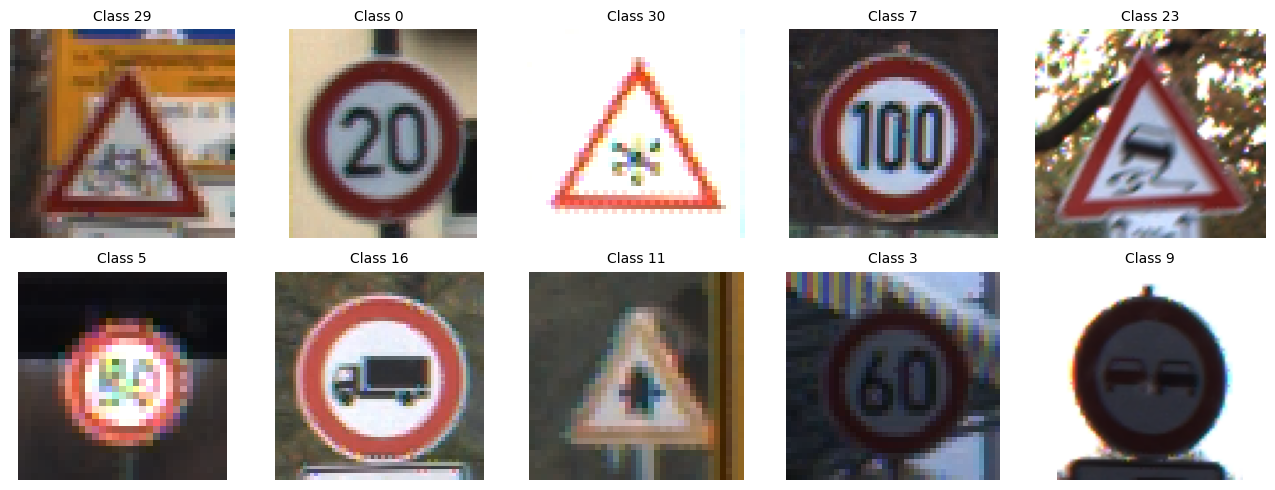

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(13, 5))
example_rows = records[records.split == 'train'].sample(10, random_state=SEED)
for ax, sample in zip(axes.ravel(), example_rows.itertuples()):
    with Image.open(sample.path) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(f'Class {sample.label}', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Data loaders

In [ ]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.90, 1.10)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])


class GTSRBPaths(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame.path.tolist()
        self.labels = frame.label.astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert('RGB')
            x = self.transform(image)
        return x, self.labels[index]


train_set = GTSRBPaths(records[records.split == 'train'], train_transform)
val_set = GTSRBPaths(records[records.split == 'val'], eval_transform)
test_set = GTSRBPaths(records[records.split == 'test'], eval_transform)

loader_options = dict(
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == 'cuda'),
    persistent_workers=(NUM_WORKERS > 0),
)
train_loader = DataLoader(train_set, shuffle=True, **loader_options)
val_loader = DataLoader(val_set, shuffle=False, **loader_options)
test_loader = DataLoader(test_set, shuffle=False, **loader_options)

images, labels = next(iter(train_loader))
print('Input shape:', tuple(images.shape))
print('Label range:', int(labels.min()), int(labels.max()))

Input shape: (64, 3, 64, 64)
Label range: 1 37


## Model

In [ ]:
MODEL_NAME = 'MobileNetV2'
weights = models.MobileNet_V2_Weights.DEFAULT
model = models.mobilenet_v2(weights=weights)
model.classifier[1] = nn.Linear(model.last_channel, NUM_CLASSES)
model = model.to(device)

model_dir = OUTPUT_ROOT / MODEL_NAME
model_dir.mkdir(parents=True, exist_ok=True)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print('Model:', MODEL_NAME)
print('Total parameters:', f'{total_params:,}')
print('Trainable parameters:', f'{trainable_params:,}')
print('Input resolution:', f'{IMAGE_SIZE}x{IMAGE_SIZE}')

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 109MB/s] 

Model: MobileNetV2
Total parameters: 2,278,955
Trainable parameters: 2,278,955
Input resolution: 64x64


## Fine-tuning

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
use_amp = (device.type == 'cuda')
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)


def epoch_pass(data_loader, training):
    model.train(training)
    running_loss = 0.0
    running_correct = 0
    n_seen = 0

    for x, y in data_loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

        running_loss += loss.item() * y.size(0)
        running_correct += (logits.argmax(1) == y).sum().item()
        n_seen += y.size(0)

    return running_loss / n_seen, running_correct / n_seen


history = []
best_val_acc = -1.0
bad_epochs = 0
best_path = model_dir / 'best_model.pth'

for epoch in range(1, EPOCHS + 1):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()

    train_loss, train_acc = epoch_pass(train_loader, training=True)
    val_loss, val_acc = epoch_pass(val_loader, training=False)
    scheduler.step()

    if device.type == 'cuda':
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    history.append({
        'epoch': epoch,
        'train_loss': train_loss,
        'train_accuracy': train_acc,
        'val_loss': val_loss,
        'val_accuracy': val_acc,
        'epoch_seconds': elapsed,
    })

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        bad_epochs = 0
        torch.save(model.state_dict(), best_path)
    else:
        bad_epochs += 1

    print(f'Epoch {epoch:02d}/{EPOCHS}  '
          f'train loss {train_loss:.4f}  train acc {train_acc:.4%}  '
          f'val loss {val_loss:.4f}  val acc {val_acc:.4%}  '
          f'time {elapsed:.1f}s')

    if bad_epochs >= PATIENCE:
        print(f'Early stopping at epoch {epoch}.')
        break

history_df = pd.DataFrame(history)
history_df.to_csv(model_dir / 'training_history.csv', index=False)
model.load_state_dict(torch.load(best_path, map_location=device, weights_only=True))
print('Best validation accuracy:', f'{best_val_acc:.4%}')

Epoch 01/15  train loss 1.7090  train acc 53.8512%  val loss 0.5333  val acc 84.2850%  time 58.6s
Epoch 02/15  train loss 0.4069  train acc 87.3481%  val loss 0.1413  val acc 95.8333%  time 49.6s
Epoch 03/15  train loss 0.1853  train acc 94.4388%  val loss 0.0605  val acc 98.1353%  time 50.4s
Epoch 04/15  train loss 0.1142  train acc 96.4312%  val loss 0.0405  val acc 98.7526%  time 49.2s
Epoch 05/15  train loss 0.0786  train acc 97.5446%  val loss 0.0310  val acc 99.0998%  time 49.2s
Epoch 06/15  train loss 0.0583  train acc 98.2197%  val loss 0.0200  val acc 99.4213%  time 48.5s
Epoch 07/15  train loss 0.0460  train acc 98.5229%  val loss 0.0141  val acc 99.6142%  time 49.0s
Epoch 08/15  train loss 0.0389  train acc 98.7516%  val loss 0.0136  val acc 99.6013%  time 49.1s
Epoch 09/15  train loss 0.0302  train acc 99.0768%  val loss 0.0109  val acc 99.6656%  time 48.9s
Epoch 10/15  train loss 0.0270  train acc 99.1540%  val loss 0.0091  val acc 99.7685%  time 48.9s
Epoch 11/15  train l

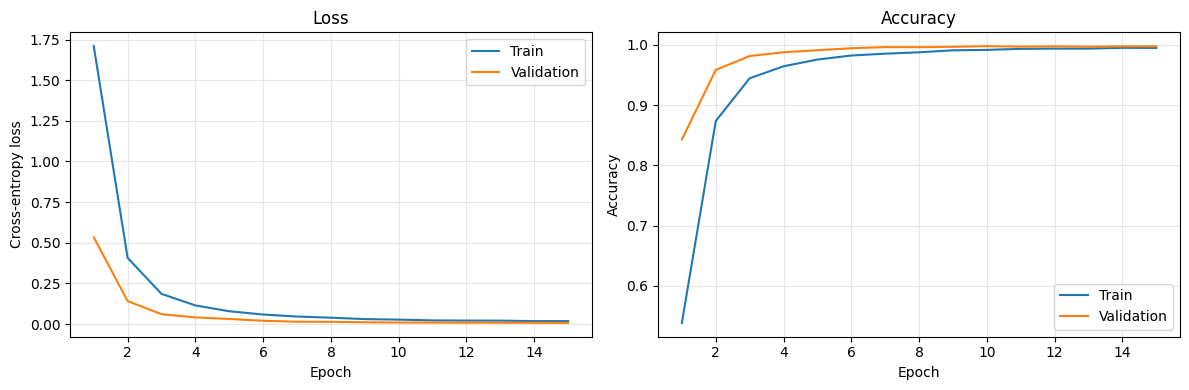

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df.epoch, history_df.train_loss, label='Train')
axes[0].plot(history_df.epoch, history_df.val_loss, label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_df.epoch, history_df.train_accuracy, label='Train')
axes[1].plot(history_df.epoch, history_df.val_accuracy, label='Validation')
axes[1].set(xlabel='Epoch', ylabel='Accuracy', title='Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(model_dir / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

## Test evaluation

In [ ]:
model.eval()
y_true = []
y_pred = []

with torch.inference_mode():
    for x, y in test_loader:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        y_true.extend(y.numpy().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())

test_accuracy = accuracy_score(y_true, y_pred)
class_report = classification_report(
    y_true, y_pred, labels=list(range(NUM_CLASSES)),
    output_dict=True, zero_division=0)
report_df = pd.DataFrame(class_report).T
report_df.to_csv(model_dir / 'classification_report.csv')

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
pd.DataFrame(cm, index=range(NUM_CLASSES), columns=range(NUM_CLASSES)).to_csv(
    model_dir / 'confusion_matrix.csv')

print(f'Test accuracy: {test_accuracy:.4%}')
print(f'Macro precision: {class_report["macro avg"]["precision"]:.4f}')
print(f'Macro recall: {class_report["macro avg"]["recall"]:.4f}')
print(f'Macro F1: {class_report["macro avg"]["f1-score"]:.4f}')
print(f'Weighted precision: {class_report["weighted avg"]["precision"]:.4f}')
print(f'Weighted recall: {class_report["weighted avg"]["recall"]:.4f}')
display(report_df.round(4))

Test accuracy: 99.8200%
Macro precision: 0.9987
Macro recall: 0.9983
Macro F1: 0.9985
Weighted precision: 0.9982
Weighted recall: 0.9982


,precision,recall,f1-score,support
0,1.0000,1.0000,1.0000,40.0000
1,0.9955,0.9977,0.9966,441.0000
2,1.0000,0.9911,0.9955,450.0000
3,0.9964,0.9928,0.9946,279.0000
4,0.9950,1.0000,0.9975,396.0000
5,0.9946,0.9946,0.9946,373.0000
6,1.0000,1.0000,1.0000,86.0000
7,1.0000,1.0000,1.0000,283.0000
8,0.9894,1.0000,0.9947,279.0000
9,1.0000,1.0000,1.0000,292.0000


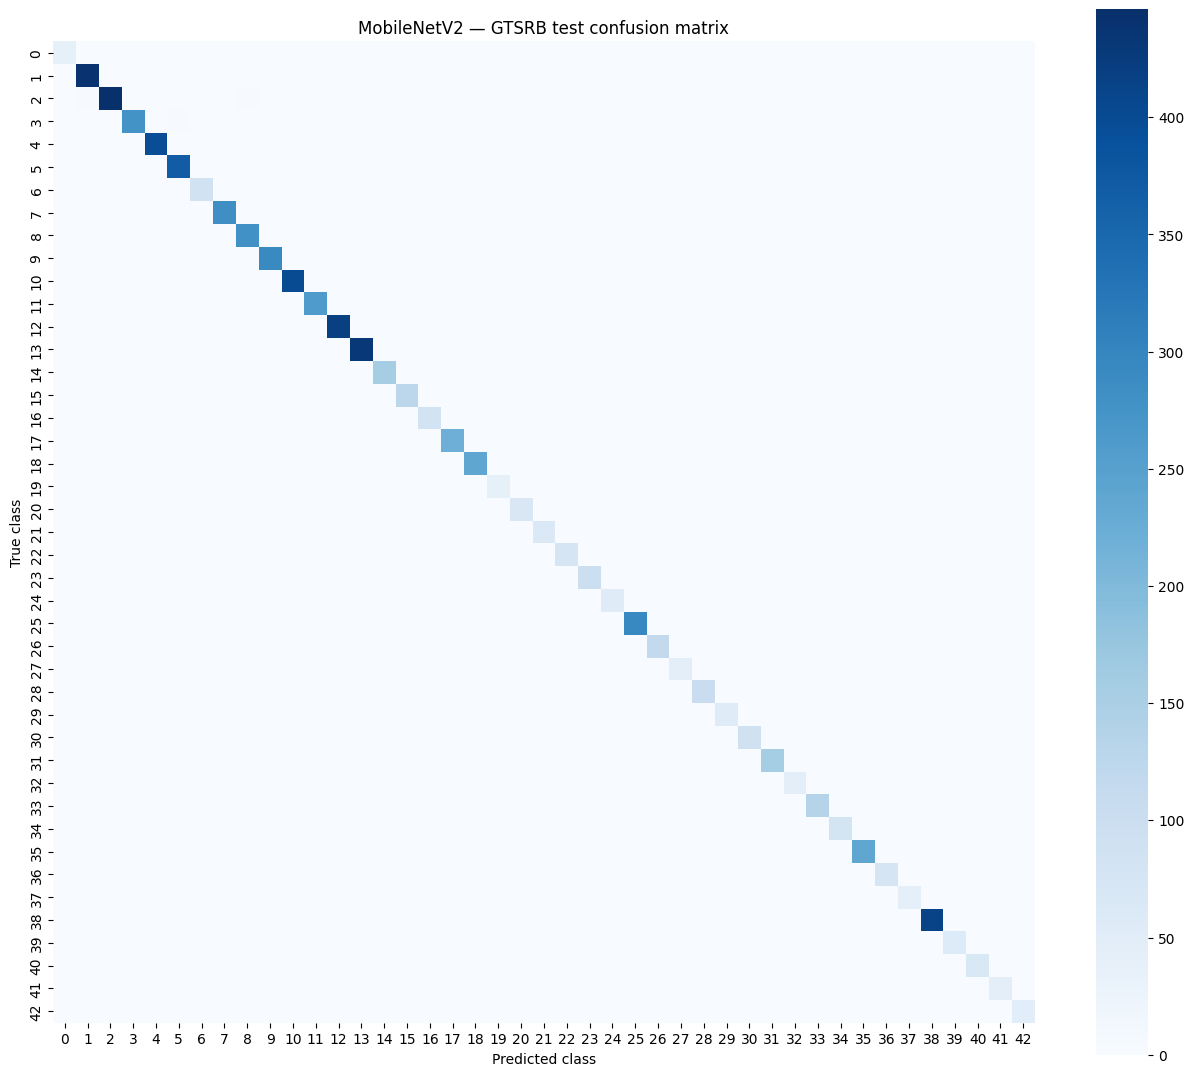

In [ ]:
plt.figure(figsize=(13, 11))
sns.heatmap(cm, cmap='Blues', square=True, cbar=True, xticklabels=range(NUM_CLASSES),
            yticklabels=range(NUM_CLASSES), annot=False)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title(f'{MODEL_NAME} — GTSRB test confusion matrix')
plt.tight_layout()
plt.savefig(model_dir / 'confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

## Model statistics

In [ ]:
checkpoint_mb = best_path.stat().st_size / (1024 ** 2)
avg_epoch_seconds = float(history_df.epoch_seconds.mean())

# Average inference latency per image on the selected device (batch inference).
model.eval()
latency_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=0, pin_memory=(device.type == 'cuda'))
warmup_batches = 3
measure_batches = 20
measured_images = 0

with torch.inference_mode():
    for index, (x, _) in enumerate(latency_loader):
        if index >= warmup_batches + measure_batches:
            break
        x = x.to(device, non_blocking=True)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            _ = model(x)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        if index >= warmup_batches:
            if index == warmup_batches:
                total_infer_seconds = 0.0
            total_infer_seconds += time.perf_counter() - start
            measured_images += x.shape[0]

latency_ms = 1000 * total_infer_seconds / measured_images if measured_images else float('nan')

summary = {
    'model': MODEL_NAME,
    'dataset': 'GTSRB',
    'data_source': DATA_SOURCE,
    'include_original_test': INCLUDE_ORIGINAL_TEST,
    'input_resolution': f'{IMAGE_SIZE}x{IMAGE_SIZE}',
    'train_samples': len(train_set),
    'val_samples': len(val_set),
    'test_samples': len(test_set),
    'total_parameters': total_params,
    'trainable_parameters': trainable_params,
    'model_size_MB': round(checkpoint_mb, 3),
    'epochs_trained': len(history_df),
    'mean_epoch_seconds': round(avg_epoch_seconds, 2),
    'test_accuracy': round(float(test_accuracy), 6),
    'macro_precision': round(float(class_report['macro avg']['precision']), 6),
    'macro_recall': round(float(class_report['macro avg']['recall']), 6),
    'macro_f1': round(float(class_report['macro avg']['f1-score']), 6),
    'inference_ms_per_image': round(float(latency_ms), 4),
    'device': str(device),
}

with open(model_dir / 'metrics.json', 'w') as f:
    json.dump(summary, f, indent=2)

summary_df = pd.DataFrame([summary])
summary_df.to_csv(model_dir / 'summary.csv', index=False)
display(summary_df.T.rename(columns={0: 'Value'}))
print('Saved results to:', model_dir)

,Value
model,MobileNetV2
dataset,GTSRB
data_source,kaggle_local
include_original_test,True
input_resolution,64x64
train_samples,36287
val_samples,7776
test_samples,7776
total_parameters,2278955
trainable_parameters,2278955


Saved results to: /content/EN3150_A03/MobileNetV2
